# 02 - Modeling

Model selection for the regression problem. The steps are:
1. Hold out 20% of the data as a final test set, untouched until the last step
2. Compare candidate models with 5-fold cross-validation on the remaining 80%
3. Measure which features the best model actually uses (permutation importance)
4. Tune the hyperparameters of the selected model
5. Evaluate the final model once on the holdout set
6. Save the chosen configuration for the training pipeline

In [ ]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import loguniform, randint

from sklearn.model_selection import train_test_split, KFold, cross_validate, RandomizedSearchCV
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

pd.options.display.float_format = "{:.3f}".format

SEED = 2026
train = pd.read_csv("../data/training_data.csv")
FEATURES = [c for c in train.columns if c.startswith("feature_")]
TARGET = "target"

## 1. Holdout split
160 rows (20%) are set aside now and only used in step 5. Every decision before that (which model,
which features, which hyperparameters) is made with cross-validation on the other 640 rows, so the
holdout score is an honest estimate of performance on unseen data.

In [ ]:
X_dev, X_hold, y_dev, y_hold = train_test_split(train[FEATURES],
                                                train[TARGET],
                                                test_size=0.2,
                                                random_state=SEED)
print("development:", X_dev.shape, "| holdout:", X_hold.shape)

development: (640, 20) | holdout: (160, 20)


## 2. Model comparison
Four models of increasing complexity, all evaluated with the same 5 folds:
- **Mean**: always predicts the average target, the minimum bar to beat
- **Linear regression**: with standardized features (section 2 of the EDA)
- **Random forest**: many independent trees whose predictions are averaged
- **Gradient boosting**: trees built one after another, each correcting the errors of the previous ones

In [ ]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = {
    "rmse": "neg_root_mean_squared_error",
    "mae": "neg_mean_absolute_error",
    "r2": "r2"
}


def evaluate(model, X, y):
    scores = cross_validate(model, X, y, cv=cv, scoring=SCORING)
    return {
        "rmse": -scores["test_rmse"].mean(),
        "rmse_std": scores["test_rmse"].std(),
        "mae": -scores["test_mae"].mean(),
        "r2": scores["test_r2"].mean(),
        "fold_rmse": -scores["test_rmse"],
    }


candidates = {
    "mean":
    DummyRegressor(),
    "linear":
    make_pipeline(StandardScaler(), LinearRegression()),
    "random_forest":
    RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1),
    "gradient_boosting":
    HistGradientBoostingRegressor(random_state=SEED),
}

results = {
    name: evaluate(model, X_dev, y_dev)
    for name, model in candidates.items()
}
summary = pd.DataFrame(results).T.drop(
    columns="fold_rmse").astype(float).sort_values("rmse")
summary

,rmse,rmse_std,mae,r2
gradient_boosting,2.152,0.033,1.666,0.819
random_forest,2.613,0.144,2.064,0.733
linear,2.830,0.112,2.220,0.686
mean,5.121,0.166,4.207,-0.025


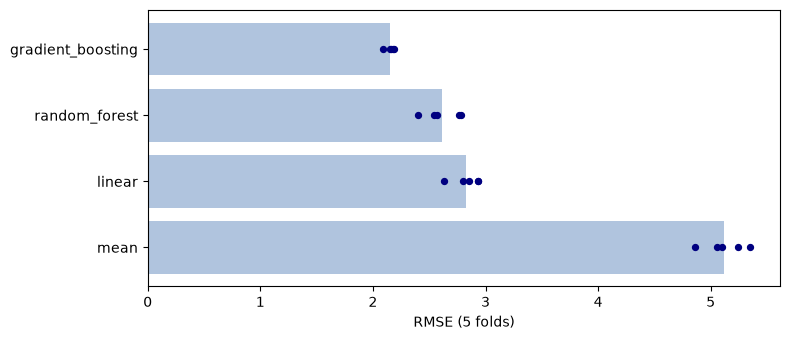

In [ ]:
# each dot is the RMSE of one fold, the bar is the average
fig, ax = plt.subplots(figsize=(8, 3.5))
for i, name in enumerate(summary.index[::-1]):
    folds = results[name]["fold_rmse"]
    ax.barh(i, folds.mean(), color="lightsteelblue")
    ax.scatter(folds, [i] * len(folds), color="navy", s=18, zorder=3)
ax.set_yticks(range(len(summary)), summary.index[::-1])
ax.set_xlabel("RMSE (5 folds)")
plt.tight_layout()

Gradient boosting has the lowest error (RMSE 2.15, R² 0.82), ahead of the random forest (2.61) and the
linear regression (2.83). It is also the most stable model: its five folds are the closest to each other
(std 0.03). The tree models beat the linear regression because they can follow the curved relationships
found in the EDA. Gradient boosting is selected for the next steps.

## 3. Feature importance
Permutation importance shuffles one column at a time and measures how much the RMSE gets worse.
If shuffling a column hurts the predictions, the model relies on it; if nothing changes, the column
is noise. It is computed inside each CV fold, on rows the model did not train on.

,mean,std
feature_2,2.257,0.100
feature_13,1.747,0.214
feature_9,1.503,0.075
feature_11,0.858,0.113
feature_18,0.655,0.056
feature_8,0.018,0.007
feature_5,0.008,0.006
feature_3,0.007,0.015


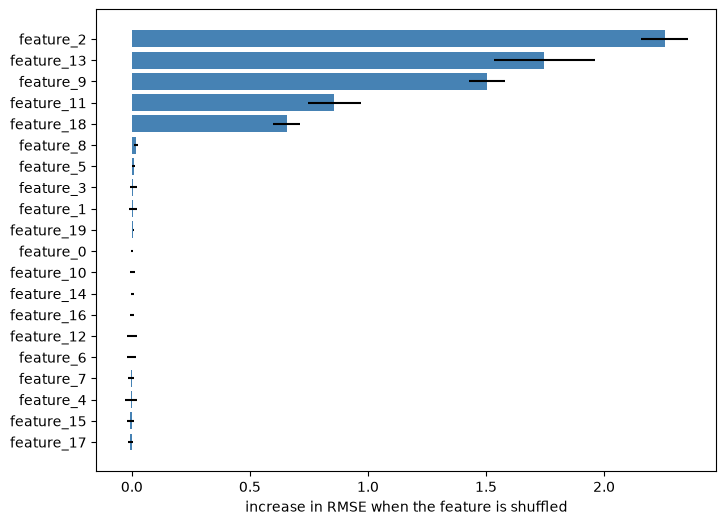

In [ ]:
fold_importances = []
for train_idx, val_idx in cv.split(X_dev):
    model = HistGradientBoostingRegressor(random_state=SEED)
    model.fit(X_dev.iloc[train_idx], y_dev.iloc[train_idx])
    result = permutation_importance(
        model,
        X_dev.iloc[val_idx],
        y_dev.iloc[val_idx],
        n_repeats=10,
        random_state=SEED,
        scoring="neg_root_mean_squared_error",
    )
    fold_importances.append(result.importances_mean)

importance = pd.DataFrame(fold_importances, columns=FEATURES)
imp = importance.agg(["mean", "std"]).T.sort_values("mean")

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(imp.index, imp["mean"], xerr=imp["std"], color="steelblue")
ax.set_xlabel("increase in RMSE when the feature is shuffled")
imp.sort_values("mean", ascending=False).head(8)

Five features stand out, with a clear gap to the rest: feature_2, feature_13, feature_9, feature_11 and
**feature_18**. Shuffling any of them raises the RMSE by at least 0.6, while the other fifteen stay
below 0.02.

feature_18 is the interesting one: its linear correlation with the target is only 0.06, so the EDA
correlation analysis ranked it as noise. The model finds it useful because its relationship with the
target is curved (higher target at both ends of its range, as seen in the binned plots of the EDA).
A linear correlation cannot capture that, a tree model can.

### Effect of removing the noise features

In [ ]:
SELECTED = imp[imp["mean"] > 0.1].sort_values("mean",
                                              ascending=False).index.tolist()
print("selected features:", SELECTED)

subset = {
    "gradient_boosting (20 features)":
    results["gradient_boosting"],
    "gradient_boosting (5 features)":
    evaluate(HistGradientBoostingRegressor(random_state=SEED), X_dev[SELECTED],
             y_dev),
}
pd.DataFrame(subset).T.drop(columns="fold_rmse").astype(float)

selected features: ['feature_2', 'feature_13', 'feature_9', 'feature_11', 'feature_18']


,rmse,rmse_std,mae,r2
gradient_boosting (20 features),2.152,0.033,1.666,0.819
gradient_boosting (5 features),2.027,0.072,1.589,0.839


Keeping only the five informative features lowers the RMSE from 2.15 to 2.03. With 640 rows, the fifteen
noise columns give the trees chances to split on random patterns that do not generalize. Removing them
also makes the model simpler to monitor in production: only five inputs need to be validated.

## 4. Hyperparameter tuning
The hyperparameters control how the trees are built. A randomized search tries 30 combinations and scores
each one with the same 5-fold cross-validation (150 fits in total).

| hyperparameter | what it controls |
|---|---|
| `max_iter` | number of trees |
| `learning_rate` | how much each tree corrects the previous ones |
| `max_leaf_nodes` | complexity of each tree |
| `min_samples_leaf` | minimum rows per leaf (avoids decisions based on very few rows) |
| `l2_regularization` | penalty that keeps predictions from becoming extreme |

In [ ]:
search_space = {
    "max_iter": randint(100, 800),
    "learning_rate": loguniform(0.01, 0.3),
    "max_leaf_nodes": randint(4, 32),
    "min_samples_leaf": randint(5, 40),
    "l2_regularization": loguniform(1e-3, 10),
}

search = RandomizedSearchCV(
    HistGradientBoostingRegressor(random_state=SEED),
    search_space,
    n_iter=30,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    random_state=SEED,
    n_jobs=-1,
)
search.fit(X_dev[SELECTED], y_dev)

print(f"best CV RMSE: {-search.best_score_:.3f}")
search.best_params_

best CV RMSE: 1.921


{'l2_regularization': np.float64(0.49489207164382853),
 'learning_rate': np.float64(0.07632820024700764),
 'max_iter': 501,
 'max_leaf_nodes': 6,
 'min_samples_leaf': 18}

In [ ]:
# top 5 combinations, to see how sensitive the model is to the hyperparameters
top = pd.DataFrame(search.cv_results_).sort_values("rank_test_score").head(5)
top["cv_rmse"] = -top["mean_test_score"]
top[[
    "cv_rmse", "std_test_score", "param_learning_rate", "param_max_iter",
    "param_max_leaf_nodes", "param_min_samples_leaf"
]]

,cv_rmse,std_test_score,param_learning_rate,param_max_iter,param_max_leaf_nodes,param_min_samples_leaf
15,1.921,0.106,0.076,501,6,18
7,1.950,0.096,0.097,411,7,14
9,1.952,0.099,0.027,626,11,37
28,1.954,0.103,0.068,323,21,36
19,1.966,0.062,0.111,189,5,9


In [ ]:
# round the values so the config is readable, and check the rounding does not change the result
BEST_PARAMS = {
    "max_iter": int(search.best_params_["max_iter"]),
    "learning_rate": round(float(search.best_params_["learning_rate"]), 3),
    "max_leaf_nodes": int(search.best_params_["max_leaf_nodes"]),
    "min_samples_leaf": int(search.best_params_["min_samples_leaf"]),
    "l2_regularization": round(float(search.best_params_["l2_regularization"]),
                               3),
}
tuned = evaluate(
    HistGradientBoostingRegressor(random_state=SEED, **BEST_PARAMS),
    X_dev[SELECTED], y_dev)
print(BEST_PARAMS)
print(f"CV RMSE with rounded params: {tuned['rmse']:.3f}")

{'max_iter': 501, 'learning_rate': 0.076, 'max_leaf_nodes': 6, 'min_samples_leaf': 18, 'l2_regularization': 0.495}
CV RMSE with rounded params: 1.916


Tuning lowers the cross-validated RMSE from 2.03 to 1.92. The best combinations share small trees
(few leaves) with a moderate learning rate and several hundred iterations: many simple trees work better
than a few complex ones on this amount of data.

## 5. Final evaluation on the holdout
The selected model (gradient boosting, 5 features, tuned hyperparameters) is trained on the 640
development rows and evaluated once on the 160 holdout rows.

In [ ]:
final_model = HistGradientBoostingRegressor(random_state=SEED, **BEST_PARAMS)
final_model.fit(X_dev[SELECTED], y_dev)
pred_hold = final_model.predict(X_hold[SELECTED])

holdout_metrics = {
    "rmse": root_mean_squared_error(y_hold, pred_hold),
    "mae": mean_absolute_error(y_hold, pred_hold),
    "r2": r2_score(y_hold, pred_hold),
}
holdout_metrics

{'rmse': 1.79345861472098, 'mae': 1.4879293298541314, 'r2': 0.8726016579202578}

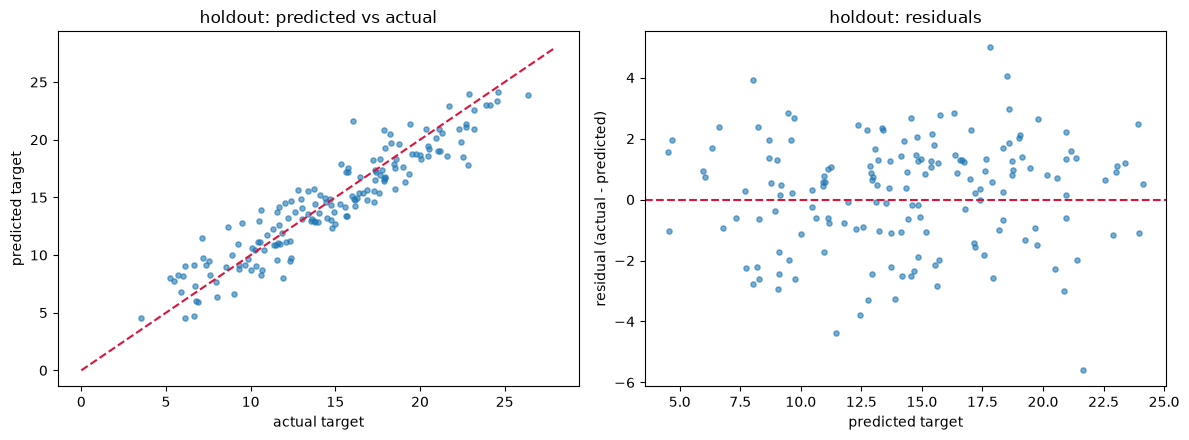

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].scatter(y_hold, pred_hold, s=14, alpha=0.6)
lims = [0, 28]
axes[0].plot(lims, lims, color="crimson", ls="--")
axes[0].set_xlabel("actual target")
axes[0].set_ylabel("predicted target")
axes[0].set_title("holdout: predicted vs actual")

residuals = y_hold - pred_hold
axes[1].scatter(pred_hold, residuals, s=14, alpha=0.6)
axes[1].axhline(0, color="crimson", ls="--")
axes[1].set_xlabel("predicted target")
axes[1].set_ylabel("residual (actual - predicted)")
axes[1].set_title("holdout: residuals")
plt.tight_layout()

On the holdout the model reaches RMSE 1.79, MAE 1.49 and R² 0.87, in line with the cross-validated
estimate (1.92). The predictions follow the diagonal and the residuals are spread evenly around zero,
without a visible pattern across the range of predictions. At the extremes the model is slightly
conservative (very low targets are predicted a bit higher and very high targets a bit lower), which is
expected from tree ensembles that average neighbouring values and cannot predict beyond what they saw.

## Summary
| step | model | RMSE |
|---|---|---|
| baseline | mean | 5.12 (CV) |
| baseline | linear regression | 2.83 (CV) |
| model selection | gradient boosting, 20 features | 2.15 (CV) |
| feature selection | gradient boosting, 5 features | 2.03 (CV) |
| tuning | gradient boosting, 5 features, tuned | 1.92 (CV) |
| **final** | **same model on the holdout** | **1.79** |

## 6. Save the configuration
The training pipeline reads this file, so the chosen features and hyperparameters are defined in one
place. In production the model is retrained on all 800 rows with this configuration.

In [ ]:
config = {
    "model": "HistGradientBoostingRegressor",
    "features": SELECTED,
    "target": TARGET,
    "params": {
        **BEST_PARAMS, "random_state": SEED
    },
    "validation": {
        "cv_rmse": round(float(tuned["rmse"]), 4),
        "holdout_rmse": round(float(holdout_metrics["rmse"]), 4),
        "holdout_mae": round(float(holdout_metrics["mae"]), 4),
        "holdout_r2": round(float(holdout_metrics["r2"]), 4),
    },
}

config_path = Path("../configs/model.json")
config_path.parent.mkdir(exist_ok=True)
config_path.write_text(json.dumps(config, indent=2))
config

C:\Users\usuario\AppData\Local\Temp\ipykernel_30820\1461410787.py:304: Pandas4Warning: Constructing a DataFrame from a list of sequences with mismatched lengths is deprecated and will raise in a future version. The shorter sequences are currently padded with NaN; make all sequences the same length before constructing instead.
  df = pd.DataFrame.from_dict({


{'model': 'HistGradientBoostingRegressor',
 'features': ['feature_2',
  'feature_13',
  'feature_9',
  'feature_11',
  'feature_18'],
 'target': 'target',
 'params': {'max_iter': 501,
  'learning_rate': 0.076,
  'max_leaf_nodes': 6,
  'min_samples_leaf': 18,
  'l2_regularization': 0.495,
  'random_state': 2026},
 'validation': {'cv_rmse': 1.9162,
  'holdout_rmse': 1.7935,
  'holdout_mae': 1.4879,
  'holdout_r2': 0.8726}}